[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/notebooks/RO/capitol3_notebook_seminar.ipynb)

# Modelarea piețelor financiare — Seminarul 3: Modele factoriale și evaluarea activelor

*Notebook de seminar. Daniel Traian Pele, Antoaneta Amza — Academia de Studii Economice din București.*

- **Partea A**: verificarea numerică a celor opt derivări.
- **Partea B**: estimare și inferență pe date din Statele Unite ale Americii (SUA) și din România.
- **Partea C**: întrebări deschise și critica unui răspuns Artificial Intelligence (AI): C2, prime factoriale la Bursa de Valori București; C1, critica unui backtest de momentum scris de AI.
- Problemele **[Rezolvat]** sînt rezolvate complet (cod și rezultat); problemele **[Propus]** au o celulă goală pentru rezolvarea individuală: rezolvările se discută la seminar.
- Exemplul rezolvat de urmat: A2 pentru A4; A3 pentru A5; A6 pentru A7; B3 pentru A8; B1 pentru B4, B11, B8; B2 pentru B5, B6, B7; A1 pentru B9; B3 pentru B10.

> Rezolvările se discută la seminar.

In [1]:
import os
import io
import zipfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

Matplotlib is building the font cache; this may take a moment.


In [2]:
REPO_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/'
# local copy of the course data, if the notebook runs inside the repository
MARKET_DIR = next((os.path.join(d, 'data', 'market') for d in ('.', '..', '../..', '../../..')
                   if os.path.isdir(os.path.join(d, 'data', 'market'))), '')
FRENCH = 'https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/'

SECTORS = ['XLB', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLU', 'XLV', 'XLY']        # from Dec 1998
SECTORS_ALL = SECTORS + ['XLRE', 'XLC']                                           # XLRE 2015, XLC 2018
SECTOR_NAMES = {'XLB': 'Materials', 'XLE': 'Energy', 'XLF': 'Financials', 'XLI': 'Industrials',
                'XLK': 'Technology', 'XLP': 'Cons. staples', 'XLU': 'Utilities', 'XLV': 'Health care',
                'XLY': 'Cons. discretionary', 'XLRE': 'Real estate', 'XLC': 'Communication'}
FACTOR_ETFS = ['MTUM', 'VLUE', 'QUAL', 'USMV', 'IWM', 'IWD', 'IWF']
BVB = ['TLV', 'SNP', 'BRD', 'TGN', 'FP', 'SNG', 'H2O', 'SNN', 'EL', 'DIGI', 'TEL']
BVB_NAMES = {'TLV': 'Banca Transilvania', 'SNP': 'OMV Petrom', 'BRD': 'BRD-GSG', 'TGN': 'Transgaz',
             'FP': 'Fondul Proprietatea', 'SNG': 'Romgaz', 'H2O': 'Hidroelectrica', 'SNN': 'Nuclearelectrica',
             'EL': 'Electrica', 'DIGI': 'Digi', 'TEL': 'Transelectrica'}

_CACHE = {}


def read_market(symbol):
    """Daily prices of one asset from the course data."""
    fname = f'{symbol}.csv'
    path = os.path.join(MARKET_DIR, fname)
    src = path if os.path.exists(path) else REPO_RAW + fname
    return pd.read_csv(src, index_col='date', parse_dates=True).sort_index()


def price(symbol):
    """Price used: adjusted close for ETFs and stocks, close for indices."""
    d = read_market(symbol)
    col = 'close' if symbol.endswith('.INDX') or symbol == 'BET' else 'adjusted_close'
    s = d[col].astype(float)
    return s[s > 0].rename(symbol)


def prices(symbols, start=None, end=None):
    """Prices aligned on the common days (multi-asset analyses align prices before taking returns)."""
    p = pd.concat([price(s) for s in symbols], axis=1).dropna()
    return p.loc[start:end]


def log_returns(p):
    """Log returns of an already aligned table (common days)."""
    return np.log(p).diff().dropna()


# =============================================================================
# KENNETH FRENCH DATA LIBRARY
# =============================================================================
FILES = {
    ('ff3', 'M'): 'F-F_Research_Data_Factors_CSV.zip',
    ('ff3', 'D'): 'F-F_Research_Data_Factors_daily_CSV.zip',
    ('ff5', 'M'): 'F-F_Research_Data_5_Factors_2x3_CSV.zip',
    ('ff5', 'D'): 'F-F_Research_Data_5_Factors_2x3_daily_CSV.zip',
    ('mom', 'M'): 'F-F_Momentum_Factor_CSV.zip',
    ('mom', 'D'): 'F-F_Momentum_Factor_daily_CSV.zip',
    ('p25', 'M'): '25_Portfolios_5x5_CSV.zip',
    ('ind10', 'M'): '10_Industry_Portfolios_CSV.zip',
    ('ind30', 'M'): '30_Industry_Portfolios_CSV.zip',
    ('p100', 'M'): '100_Portfolios_10x10_CSV.zip',
    # univariate sorts (first table: value-weighted), Jensen-Kelly-Pedersen case study
    ('ME', 'M'): 'Portfolios_Formed_on_ME_CSV.zip',
    ('BE-ME', 'M'): 'Portfolios_Formed_on_BE-ME_CSV.zip',
    ('OP', 'M'): 'Portfolios_Formed_on_OP_CSV.zip',
    ('INV', 'M'): 'Portfolios_Formed_on_INV_CSV.zip',
    ('E-P', 'M'): 'Portfolios_Formed_on_E-P_CSV.zip',
    ('CF-P', 'M'): 'Portfolios_Formed_on_CF-P_CSV.zip',
    ('D-P', 'M'): 'Portfolios_Formed_on_D-P_CSV.zip',
    ('AC', 'M'): 'Portfolios_Formed_on_AC_CSV.zip',
    ('NI', 'M'): 'Portfolios_Formed_on_NI_CSV.zip',
    ('BETA', 'M'): 'Portfolios_Formed_on_BETA_CSV.zip',
    ('VAR', 'M'): 'Portfolios_Formed_on_VAR_CSV.zip',
    ('RESVAR', 'M'): 'Portfolios_Formed_on_RESVAR_CSV.zip',
    ('PRIOR_12_2', 'M'): '10_Portfolios_Prior_12_2_CSV.zip',
    ('PRIOR_1_0', 'M'): '10_Portfolios_Prior_1_0_CSV.zip',
    ('PRIOR_60_13', 'M'): '10_Portfolios_Prior_60_13_CSV.zip',
}


def _parse_first_table(text, date_len):
    """First table of a French data set: header ',col1,col2...', then rows YYYYMM(DD),values."""
    lines = text.splitlines()
    i = next(k for k, l in enumerate(lines) if l.startswith(',') and len(l.split(',')) > 1)
    cols = [c.strip() for c in lines[i].split(',')[1:]]
    rows = []
    for l in lines[i + 1:]:
        parts = [x.strip() for x in l.split(',')]
        if not parts or len(parts[0]) != date_len or not parts[0].isdigit():
            break
        rows.append([parts[0]] + [float(x) for x in parts[1:]])
    df = pd.DataFrame(rows, columns=['date'] + cols)
    fmt = '%Y%m' if date_len == 6 else '%Y%m%d'
    df['date'] = pd.to_datetime(df['date'], format=fmt)
    if date_len == 6:
        df['date'] = df['date'] + pd.offsets.MonthEnd(0)
    df = df.set_index('date')
    return df.replace([-99.99, -999.0], np.nan) / 100.0          # percent -> decimal


def french(name='ff5', freq='M'):
    """Fama-French factors / momentum / portfolios, in decimals (0.01 = 1%)."""
    key = (name, freq)
    if key in _CACHE:
        return _CACHE[key]
    url = FRENCH + FILES[key]
    raw = urllib.request.urlopen(urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'}),
                                 timeout=120).read()
    z = zipfile.ZipFile(io.BytesIO(raw))
    text = z.read(z.namelist()[0]).decode('latin-1')
    df = _parse_first_table(text, 6 if freq == 'M' else 8)
    df.columns = [c.replace('Mom', 'MOM').strip() for c in df.columns]
    _CACHE[key] = df
    return df


def factors(freq='M'):
    """Mkt-RF, SMB, HML, RMW, CMA, RF, MOM and SMB_FF3 over the common period.

    The five-factor SMB (sorts on B/M, profitability and investment) enters FF5;
    SMB_FF3 is the published three-factor SMB (2x3 sorts on size and B/M),
    used in FF3 and Carhart. HML, Mkt-RF and RF are the same in the two data sets.
    """
    f3 = french('ff3', freq)[['SMB']].rename(columns={'SMB': 'SMB_FF3'})
    return pd.concat([french('ff5', freq), french('mom', freq), f3], axis=1).dropna()


# =============================================================================
# REGRESSIONS
# =============================================================================
def ols_hac(y, X, lags=None, const=True):
    """OLS with Newey-West (Bartlett) standard errors. Returns (coef, se, t, resid, r2)."""
    y = np.asarray(y, float)
    X = np.asarray(X, float)
    if X.ndim == 1:
        X = X[:, None]
    if const:
        X = np.column_stack([np.ones(len(y)), X])
    n, k = X.shape
    if lags is None:
        lags = int(np.floor(4 * (n / 100) ** (2 / 9)))
    XtX_inv = np.linalg.inv(X.T @ X)
    b = XtX_inv @ X.T @ y
    e = y - X @ b
    u = X * e[:, None]
    S = u.T @ u
    for l in range(1, lags + 1):
        w = 1 - l / (lags + 1)
        G = u[l:].T @ u[:-l]
        S += w * (G + G.T)
    V = XtX_inv @ S @ XtX_inv
    se = np.sqrt(np.diag(V))
    r2 = 1 - e.var() / y.var()
    return b, se, b / se, e, r2


def grs_test(excess, market_excess):
    """Gibbons-Ross-Shanken (1989) test of alpha = 0 on N assets, one factor.

    Sigma and the factor variance are maximum-likelihood estimators (division by T);
    under i.i.d. Normal residuals, W ~ F(N, T - N - 1) exactly.
    """
    from scipy import stats
    R = np.asarray(excess, float)
    f = np.asarray(market_excess, float)
    T, N = R.shape
    X = np.column_stack([np.ones(T), f])
    B = np.linalg.lstsq(X, R, rcond=None)[0]
    alpha = B[0]
    E = R - X @ B
    Sigma = E.T @ E / T
    mu, s2 = f.mean(), f.var(ddof=0)
    stat = (T - N - 1) / N * (alpha @ np.linalg.solve(Sigma, alpha)) / (1 + mu ** 2 / s2)
    p = 1 - stats.f.cdf(stat, N, T - N - 1)
    return stat, p, alpha, B[1]

In [3]:
# Chart style: transparent background, legend below the plot
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['savefig.facecolor'] = 'none'
plt.rcParams['savefig.transparent'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['font.size'] = 9
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.linewidth'] = 0.6
plt.rcParams['lines.linewidth'] = 1.1
plt.rcParams['legend.facecolor'] = 'none'
plt.rcParams['legend.framealpha'] = 0
plt.rcParams['legend.fontsize'] = 8

# Chart colours
MainBlue = '#1A3A6E'
IDAred   = '#CD0000'
Forest   = '#2E7D32'
Amber    = '#B5853F'
Orange   = '#E67E22'
Purple   = '#8E44AD'
Crimson  = '#DC3545'
Navy     = '#1F2A44'   # reference lines (no grey in charts)
BandBlue = '#C5D2E8'   # light MainBlue tint for confidence / reference bands
Gray, LightGray = Navy, BandBlue   # legacy names kept for importing scripts
PALETTE = [MainBlue, IDAred, Forest, Amber, Orange, Purple, Crimson, '#795548', '#17A2B8', '#6F42C1', '#20C997']

# models: FF3 and Carhart use the published three-factor SMB; FF5 uses the five-factor SMB
FF3 = ['Mkt-RF', 'SMB_FF3', 'HML']
CARHART = FF3 + ['MOM']
FF5 = ['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA']
FF6 = FF5 + ['MOM']

SEED = 42
MAX_ABS_RET = 0.5        # data-error threshold for the BVB series (daily log return)
END = '2026-07-31'       # last month of the monthly sample used in the chapter (T = 757 months from July 1963)


def save_fig(name):
    """Save the figure as transparent PDF and PNG in the current folder."""
    plt.savefig(f'{name}.pdf', bbox_inches='tight', transparent=True)
    plt.savefig(f'{name}.png', bbox_inches='tight', transparent=True, dpi=180)
    plt.show()
    plt.close()
    print(f"   saved {name}")


def legend_outside_bottom(ax, ncol=2, y=-0.22):
    """Place the legend outside the plot, bottom centre."""
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def monthly_excess(symbols, start='1999-01-01'):
    """Monthly simple excess returns over RF (one-month T-bill), on the common months."""
    p = prices(symbols).resample('ME').last()
    r = p.pct_change().dropna()
    F = factors('M')
    idx = r.index.intersection(F.index)
    r = r.loc[idx].loc[start:END]
    F = F.loc[r.index]
    return r.sub(F['RF'], axis=0), F


def daily_excess_one(symbol, start=None):
    """Daily excess return of a single asset, on the factor calendar.

    Only days with a price on the previous trading day are kept
    (otherwise the return would span several days and the factors only one).
    """
    s = price(symbol)
    F = factors('D').loc[:END]                         # same sample end as the monthly data
    s = s.loc[s.index.isin(F.index)]
    cal = pd.Series(np.arange(len(F)), index=F.index)
    pos = cal.loc[s.index].values
    r = s.pct_change()
    consecutive = np.r_[False, np.diff(pos) == 1]
    r = r[consecutive].dropna()
    if start:
        r = r.loc[start:]
    Fx = F.loc[r.index]
    return (r - Fx['RF']).rename(symbol), Fx


def daily_excess(symbols, start=None):
    """Compatibility: dictionary {symbol: (excess, factors)} on each asset's calendar."""
    return {s: daily_excess_one(s, start) for s in symbols}


def save_fig(name):
    """Afiseaza figura."""
    plt.show()
    plt.close()

In [4]:
def block_bootstrap_alpha(y, X, B=2000, block=20, periods=252, seed=SEED, draws=False):
    """Moving-block bootstrap (Kunsch) for the annualised alpha of an OLS regression.

    The pairs (y, X) are resampled together (blocks of whole rows). draws=True also returns the draws.
    """
    rng = np.random.default_rng(seed)
    y, X = np.asarray(y), np.asarray(X)
    n = len(y)
    nb = int(np.ceil(n / block))
    out = np.empty(B)
    Z = np.column_stack([np.ones(n), X])
    for b in range(B):
        starts = rng.integers(0, n - block + 1, nb)          # the last valid block starts at n - block
        idx = (starts[:, None] + np.arange(block)).ravel()[:n]
        coef = np.linalg.lstsq(Z[idx], y[idx], rcond=None)[0]
        out[b] = coef[0] * periods
    if draws:
        return np.percentile(out, [2.5, 97.5]), out.std(), out
    return np.percentile(out, [2.5, 97.5]), out.std()


def beta_split():
    S = [s + '.US' for s in SECTORS]
    ex, F = monthly_excess(S + ['SPY.US'])
    halves = [ex.loc[:'2012-12-31'], ex.loc['2013-01-01':]]
    b = []
    for h in halves:
        b.append(pd.Series({s[:-3]: ols_hac(h[s].values, h['SPY.US'].values)[0][1] for s in S}))
    se1 = pd.Series({s[:-3]: ols_hac(halves[0][s].values, halves[0]['SPY.US'].values)[1][1] for s in S})
    return b[0], b[1], se1, halves


def vasicek_prior(b, se):
    """Vasicek prior estimated from the data (empirical Bayes).

    Var_cs(beta_hat) = Var_cs(beta) + mean se^2: the dispersion of estimated betas includes estimation noise,
    so the prior variance of the true betas is Var_cs(beta_hat) - mean se(beta_hat)^2.
    """
    m = float(b.mean())
    v = float(b.var(ddof=1) - (se ** 2).mean())
    return m, max(v, 1e-6)


def sml_data(start='1963-07-31'):
    F = factors('M')
    P = french('p25', 'M').loc[start:END]
    Fx = F.loc[P.index]
    ex = P.sub(Fx['RF'], axis=0)
    mk = Fx['Mkt-RF']
    rows = []
    for c in ex.columns:
        b, se, t, e, r2 = ols_hac(ex[c].values, mk.values)
        rows.append((c, b[1], b[0] * 12, t[0], ex[c].mean() * 12))
    res = pd.DataFrame(rows, columns=['port', 'beta', 'alpha', 't_alpha', 'avg']).set_index('port')
    return res, ex, mk


def pca_sectors():
    S = [s + '.US' for s in SECTORS_ALL]
    r = log_returns(prices(S + ['SPY.US']))
    X = r[S]
    Z = (X - X.mean()) / X.std()
    C = np.corrcoef(Z.values.T)
    vals, vecs = np.linalg.eigh(C)
    order = np.argsort(vals)[::-1]
    vals, vecs = vals[order], vecs[:, order]
    for k in range(vecs.shape[1]):                      # sign: positive mean loading
        if vecs[:, k].sum() < 0:
            vecs[:, k] *= -1
    pcs = Z.values @ vecs
    corr_pc1_spy = np.corrcoef(pcs[:, 0], r['SPY.US'].values)[0, 1]
    return vals, vecs, r, corr_pc1_spy


def n_factors(X, kmax):
    """Number of factors: Kaiser (eigenvalues > 1), Bai & Ng (2002) IC_p2, Ahn & Horenstein (2013) ER."""
    X = np.asarray(X, float)
    X = (X - X.mean(0)) / X.std(0)
    T, N = X.shape
    ev = np.sort(np.linalg.eigvalsh(X.T @ X / T))[::-1]         # eigenvalues of the correlation matrix
    V = [ev[k:].sum() / N for k in range(kmax + 1)]              # V(k) = (1/NT) sum of squared residuals
    pen = (N + T) / (N * T) * np.log(min(N, T))
    ic = [np.log(V[k]) + k * pen for k in range(kmax + 1)]
    er = [ev[k - 1] / ev[k] for k in range(1, kmax + 1)]
    return dict(T=T, N=N, kaiser=int((ev > 1).sum()), bai_ng=int(np.argmin(ic)),
                ahn_horenstein=int(np.argmax(er) + 1), eig=ev[:kmax + 1].round(3).tolist(),
                er=np.round(er, 2).tolist())


def eiv_attenuation():
    """Errors in variables in pass 2, conditional on the realised factor path:
    plim_N lambda_OLS / lambda_realised = Var(beta) / (Var(beta) + s2_eps / sum_t (f_t - f_bar)^2)."""
    out = {}
    res, ex, mk = sml_data()
    cases = {'25 size x B/M': (ex, mk)}
    S = [s + '.US' for s in SECTORS]
    exs, Fs = monthly_excess(S)
    cases['9 sector ETFs'] = (exs, Fs['Mkt-RF'])
    for k, (e, m) in cases.items():
        R = e.values
        f = np.asarray(m, float)
        T = len(f)
        Z = np.column_stack([np.ones(T), f])
        AB = np.linalg.lstsq(Z, R, rcond=None)[0]
        E = R - Z @ AB
        s2e = (E ** 2).sum(0) / (T - 2)
        noise = s2e.mean() / ((f - f.mean()) ** 2).sum()          # = s2_eps / (T * var_ML(f))
        vb_hat = AB[1].var(ddof=1)
        vb = vb_hat - noise
        out[k] = dict(T=T, N=R.shape[1], var_beta_hat=vb_hat, noise=noise, var_beta=vb,
                      attenuation=vb / (vb + noise), sd_beta=np.sqrt(vb_hat))
    return out


def stationary_bootstrap_idx(T, mean_block, rng):
    """Indices for the stationary bootstrap (Politis & Romano, 1994), mean block length mean_block."""
    idx = np.empty(T, dtype=int)
    idx[0] = rng.integers(T)
    for t in range(1, T):
        idx[t] = rng.integers(T) if rng.random() < 1 / mean_block else (idx[t - 1] + 1) % T
    return idx

## Partea A — derivări (verificare numerică)

### A1. Zece factori candidați: Bonferroni, Holm, Benjamini–Hochberg [Rezolvat]

In [5]:
# A1 testare multiplă, pas cu pas
p = np.array([0.001, 0.004, 0.009, 0.012, 0.021, 0.035, 0.048, 0.060, 0.20, 0.55]); m = len(p); ps = np.sort(p)
holm = 0
for k, pk in enumerate(ps):
    if pk <= 0.05 / (m - k):
        holm += 1
    else:
        break
bh = max([k + 1 for k in range(m) if ps[k] <= 0.05 * (k + 1) / m], default=0)
cm = (1 / np.arange(1, m + 1)).sum()   # Benjamini-Yekutieli: orice dependență
by = max([k + 1 for k in range(m) if ps[k] <= 0.05 * (k + 1) / (m * cm)], default=0)
print('naive =', (p <= 0.05).sum(), ' Bonferroni =', (p <= 0.05 / m).sum(), ' Holm =', holm, ' BH =', bh, ' BY =', by)

naive = 7  Bonferroni = 2  Holm = 2  BH = 5  BY = 1


### A2. Capital Asset Pricing Model (CAPM) din portofoliul tangent [Rezolvat]

- Cu momentele de eșantion ale celor 9 ETF-uri sectoriale, portofoliul tangent din eșantion evaluează exact fiecare sector: $\hat\mu_i = \hat\beta_i\hat\mu_m$.

In [6]:
# A2 CAPM din portofoliul tangent
ex, F = monthly_excess([s + '.US' for s in SECTORS])
mu, Sig = ex.mean().values, ex.cov().values
w = np.linalg.solve(Sig, mu); w /= w.sum()
rm = ex.values @ w
beta = np.array([np.cov(ex.values[:, i], rm)[0, 1] / rm.var(ddof=1) for i in range(ex.shape[1])])
pd.DataFrame({'mu (ann.)': 12 * mu, 'beta * mu_m (ann.)': 12 * beta * rm.mean(), 'beta': beta},
             index=SECTORS).round(4)

,mu (ann.),beta * mu_m (ann.),beta
XLB,0.0819,0.0819,0.9587
XLE,0.0963,0.0963,1.1267
XLF,0.0615,0.0615,0.7199
XLI,0.0878,0.0878,1.0272
XLK,0.1043,0.1043,1.2205
XLP,0.0528,0.0528,0.6183
XLU,0.0656,0.0656,0.7681
XLV,0.0716,0.0716,0.8373
XLY,0.0890,0.0890,1.0411


### A4. Gibbons–Ross–Shanken (test) (GRS) ca cîștig de raport Sharpe [Propus]

- **Întrebarea**: de ce măsoară GRS cît de mult îmbunătățesc activele de test raportul Sharpe al pieței?

- **Notații**: $Y_t = (f_t, \mathbf{R}^{e\top}_t)^\top$, $(N+1) \times 1$; momentele Maximum Likelihood (ML) $\boldsymbol\mu_Y = (\mu_f, \boldsymbol\mu_R^\top)^\top$ și $\mathbf{V} = \begin{pmatrix} \sigma_f^2 & \boldsymbol\sigma_{Rf}^\top \\ \boldsymbol\sigma_{Rf} & \boldsymbol\Sigma_R \end{pmatrix}$, toate împărțite la $T$; $\boldsymbol\beta = \boldsymbol\sigma_{Rf}/\sigma_f^2$, $\boldsymbol\alpha = \boldsymbol\mu_R - \boldsymbol\beta\mu_f$, $\boldsymbol\Sigma = \boldsymbol\Sigma_R - \boldsymbol\beta\boldsymbol\beta^\top\sigma_f^2$

- **Identitate dată** (inversa pe blocuri, cu complementul Schur $\boldsymbol\Sigma$ al lui $\sigma_f^2$) \[ \mathbf{V}^{-1} = \begin{pmatrix} 1/\sigma_f^2 + \boldsymbol\beta^\top\boldsymbol\Sigma^{-1}\boldsymbol\beta & -\boldsymbol\beta^\top\boldsymbol\Sigma^{-1} \\ -\boldsymbol\Sigma^{-1}\boldsymbol\beta & \boldsymbol\Sigma^{-1} \end{pmatrix} \]

- **Cerințe**

  1.  Dezvoltați $SR^2(f, \mathbf{R}) = \boldsymbol\mu_Y^\top\mathbf{V}^{-1}\boldsymbol\mu_Y$ în patru termeni și arătați că este egal cu $\mu_f^2/\sigma_f^2 + \boldsymbol\alpha^\top\boldsymbol\Sigma^{-1}\boldsymbol\alpha$.

  2.  Scrieți statistica GRS $W$ în funcție de $SR^2(f)$ și $SR^2(f, \mathbf{R})$.

  3.  Cele 25 de portofolii mărime $\times$ B/M: $T = 757$, $N = 25$, $SR(f) = 0{,}134$ și $SR(f, \mathbf{R}) = 0{,}405$ lunar; calculați $W$ și decideți la 5% (valoarea critică a lui $F(25, 731)$: $1{,}52$).

  4.  Comparați cîștigul observat cu cel așteptat sub $H_0$, $N(1 + SR^2(f))/(T - N - 3)$.

- **De raportat**: calculul algebric, $W$, decizia și o frază

- Model: [A2](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-A2), [B2](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-B2); Notebook: secțiunea [A4](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-A4)

[Exercițiul A4 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-A4)

In [7]:
# Codul vostru aici


### A7. Un factor inutil în etapa 2 [Propus]

- **Întrebarea**: de ce poate părea remunerat în etapa 2 un factor fără legătură cu randamentele?

- **Ipoteze**: $N$ fix, $T \to \infty$; $\mathbf{R}_t$ i.i.d. în timp, cu mediile $\mu_i$, covarianță nesingulară $\boldsymbol\Sigma$, momente de ordinul patru finite; un factor $g_t$ i.i.d., cu media 0 și varianța $\sigma_g^2$, independent de toate randamentele, deci $\beta_{i,g} = 0$; în demonstrație $g$ este singurul factor din etapa 2

- **Cerințe**

  1.  Arătați că $\sqrt T\,\hat\beta_{i,g} \to N(0, \sigma_i^2/\sigma_g^2)$: $\hat\beta_{i,g}$ este de ordinul $T^{-1/2}$ (numărătorul și numitorul separat).

  2.  Scrieți $\hat\lambda_g = \widehat{\operatorname{Cov}}_{cs}(\bar R_i, \hat\beta_{i,g})/\widehat{\operatorname{Var}}_{cs}(\hat\beta_{i,g})$ cu $\mathbf{z} = \sqrt T\,\hat{\boldsymbol\beta}_g$; arătați că $\hat\lambda_g$ este de ordinul $\sqrt T$ cînd mediile $\mu_i$ diferă.

  3.  Cazul mediilor egale: folosind limita comună a lui $(\sqrt T(\bar{\mathbf{R}} - \boldsymbol\mu), \mathbf{z})$, arătați că $\hat\lambda_g$ converge la o variabilă aleatoare nedegenerată, nu la 0.

  4.  Simularea din curs adaugă $g$ la CAPM pe cele 25 de portofolii (2 000 de replicări): $\lambda_g = 0$ este respins în $59{,}6\%$ dintre replicări cu erori Fama--MacBeth și în $26{,}6\%$ cu erori Shanken, iar testul Wald din prima etapă pentru $\beta_{i,g} = 0$ respinge în $6{,}7\%$; explicați aceste rate și precizați ce test din prima etapă protejează împotriva lor.

- **De raportat**: cele trei rezultate asimptotice și explicația ratelor de respingere

- Model: [A6](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-A6); Notebook: secțiunea [A7](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-A7)

[Exercițiul A7 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-A7)

In [8]:
# Codul vostru aici


### A6. Erori în variabile în etapa 2 [Rezolvat]

In [9]:
# A6 factorii de atenuare
pd.DataFrame(eiv_attenuation()).T.round(4)

,T,N,var_beta_hat,noise,var_beta,attenuation,sd_beta
25 size x B/M,757.0,25.0,0.0191,0.0006,0.0184,0.9674,0.1380
9 sector ETFs,331.0,9.0,0.0925,0.0020,0.0905,0.9784,0.3041


### A8. Active cu corelații egale [Propus]

- **Întrebarea**: cum depinde ponderea primei componente de corelația medie și de $N$?

- **Etapa 1**, $N = 3$, $\rho = 0{,}5$: $\mathbf{C} = \begin{pmatrix} 1 & 0{,}5 & 0{,}5 \\ 0{,}5 & 1 & 0{,}5 \\ 0{,}5 & 0{,}5 & 1 \end{pmatrix}$

  1.  Verificați că $\mathbf{v}_1 = (1, 1, 1)/\sqrt3$, $\mathbf{v}_2 = (1, -1, 0)/\sqrt2$, $\mathbf{v}_3 = (1, 1, -2)/\sqrt6$ sînt vectori proprii ortonormați și găsiți valorile proprii.

  2.  Calculați ponderea first principal component (PC1), $\ell_1/3$.

- **Etapa 2**, $N$ active, $\mathbf{C} = (1 - \rho)\mathbf{I} + \rho\mathbf{1}\mathbf{1}^\top$

  3.  Arătați că $\ell_1 = 1 + (N-1)\rho$ și că toate celelalte valori proprii sînt egale cu $1 - \rho$; găsiți limita ponderii PC1 cînd $N \to \infty$.

  4.  Inversați formula ponderii pentru a obține $\rho$ echivalent pentru o pondere PC1 $s$; aplicați-o la acțiunile blue chip de la Bursa de Valori București (BVB) ($N = 10$, $s = 0{,}425$, [B10](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-B10)) și la sectoarele din SUA ($N = 11$, $s = 0{,}660$, [B3](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-B3)).

  5.  Extindere: pentru o $\mathbf{C}$ oarecare cu corelația medie în afara diagonalei $\bar\rho$, arătați că $1 + (N-1)\bar\rho \le \ell_1$.

- **De raportat**: valorile proprii, formula ponderii PC1 cu limita ei și cele două valori $\rho$

- Model: [B3](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-B3); Notebook: secțiunea [A8](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-A8)

[Exercițiul A8 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-A8)

In [10]:
# Codul vostru aici


## Partea B — estimare și inferență

### B1. Beta și alfa pentru XLK: erori clasice, Newey–West (regula pentru numărul de laguri) și bootstrap pe blocuri [Rezolvat]

- Interpretare: eroarea Heteroskedasticity and Autocorrelation Consistent (standard errors) (HAC) a lui beta este dublă față de cea clasică; ce proprietate a reziduurilor o produce?

In [11]:
# Rezolvare
def b1_xlk():
    ex, F = monthly_excess(['XLK.US', 'SPY.US'])
    y, x = ex['XLK.US'].values, F['Mkt-RF'].values
    lags = int(np.floor(4 * (len(y) / 100) ** (2 / 9)))           # Newey-West lag rule: T = 331 -> 5
    b, se, t, e, r2 = ols_hac(y, x, lags=lags)
    Z = np.column_stack([np.ones(len(y)), x])
    s2 = e @ e / (len(y) - 2)
    se_cl = np.sqrt(np.diag(s2 * np.linalg.inv(Z.T @ Z)))
    ci, bse = block_bootstrap_alpha(y, x, block=12, periods=12)
    return dict(T=len(y), lags=lags, start=str(ex.index[0].date()), end=str(ex.index[-1].date()),
                alpha=b[0] * 12, beta=b[1], se_alpha_cl=se_cl[0] * 12, se_alpha_nw=se[0] * 12,
                se_beta_cl=se_cl[1], se_beta_nw=se[1], t_alpha_nw=t[0], r2=r2, boot_ci=ci.tolist(), boot_se=bse)


b1_xlk()

{'T': 331,
 'lags': 5,
 'start': '1999-01-31',
 'end': '2026-07-31',
 'alpha': np.float64(0.00328211178941935),
 'beta': np.float64(1.277373557864404),
 'se_alpha_cl': np.float64(0.022705609302650098),
 'se_alpha_nw': np.float64(0.02453119193015265),
 'se_beta_cl': np.float64(0.04149599890282397),
 'se_beta_nw': np.float64(0.08219343664415406),
 't_alpha_nw': np.float64(0.13379340876564275),
 'r2': np.float64(0.7422834632313802),
 'boot_ci': [-0.054587842668730485, 0.04854600818377907],
 'boot_se': np.float64(0.026115718947500043)}

### B2. Testul GRS pe ETF-urile sectoriale [Rezolvat]

- Interpretare: de ce testul respinge CAPM pe cele 25 de portofolii, dar nu aici?

In [12]:
# Rezolvare
def b2_grs():
    S = [s + '.US' for s in SECTORS]
    ex, F = monthly_excess(S)
    stat, p, alpha, beta = grs_test(ex.values, F['Mkt-RF'].values)
    return dict(T=len(ex), N=len(S), grs=stat, p=p, alphas=dict(zip(SECTORS, np.round(alpha * 12, 4))),
                betas=dict(zip(SECTORS, np.round(beta, 3))))


b2_grs()

{'T': 331,
 'N': 9,
 'grs': np.float64(0.5332788692814445),
 'p': np.float64(0.8500677350293644),
 'alphas': {'XLB': np.float64(-0.0008),
  'XLE': np.float64(0.0236),
  'XLF': np.float64(-0.0229),
  'XLI': np.float64(0.0052),
  'XLK': np.float64(0.0033),
  'XLP': np.float64(0.017),
  'XLU': np.float64(0.0339),
  'XLV': np.float64(0.0183),
  'XLY': np.float64(0.0043)},
 'betas': {'XLB': np.float64(1.047),
  'XLE': np.float64(0.919),
  'XLF': np.float64(1.068),
  'XLI': np.float64(1.045),
  'XLK': np.float64(1.277),
  'XLP': np.float64(0.453),
  'XLU': np.float64(0.401),
  'XLV': np.float64(0.673),
  'XLY': np.float64(1.07)}}

### B5. Fama–MacBeth pe ETF-uri sectoriale și factoriale [Propus]

- **Întrebarea**: există prime de piață, de mărime și de valoare în 16 ETF-uri americane în 2013--2026?

- **Date**: 9 ETF-uri sectoriale și 7 ETF-uri factoriale (MTUM momentum, VLUE valoare, QUAL calitate, USMV volatilitate minimă, IWM Russell 2000, IWD Russell 1000 Value, IWF Russell 1000 Growth), randamente lunare în exces, august 2013 -- iulie 2026 ($T = 156$): un panel $156 \times 16$; factorii Mkt-RF, Small Minus Big (size factor) (SMB) din modelul Fama–French three-factor model (FF3) (setul cu trei factori din [Kenneth French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html)), High Minus Low (value factor) (HML): $156 \times 3$

- **Cerințe**

  1.  Etapa 1: estimați, pe tot eșantionul, regresia fiecărui Exchange-Traded Fund (ETF) pe cei trei factori; raportați $\hat{\mathbf{B}}$ ($16 \times 3$).

  2.  Etapa 2: în fiecare lună, estimați regresia Ordinary Least Squares (OLS) a celor 16 randamente pe $\mathbf{X} = [\mathbf{1}, \hat{\mathbf{B}}]$; prezentați complet calculul pentru o lună (valori ajustate față de valori observate), apoi calculați media celor 156 de pante; anualizați prin înmulțire cu 12.

  3.  Calculați erorile standard Fama--MacBeth, Newey--West pe $\hat\lambda_t$ (6 laguri) și Shanken ([[regresiile în două etape (Fama--MacBeth)]{style="color: MainBlue"}](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=sem3p16); pentru termenul liber, bordați covarianța factorilor cu o linie și o coloană nule: $\operatorname{Var}_{Sh}(\hat\lambda_0)=(1+c)\operatorname{Var}_{FM}(\hat\lambda_0)$); ca extindere, calculați erorile Kan--Robotti--Shanken cu funcția `two_pass_gmm` din notebook.

  4.  Comparați fiecare $\hat\lambda$ cu media în timp a factorului său, într-un grafic, și testați $\lambda = 0$ la 5%.

- **De raportat**: $\hat{\mathbf{B}}$, luna calculată complet, tabelul primelor cu erorile lor standard, graficul și deciziile testelor

- **Interpretare**: este o primă nesemnificativă aici dovadă că mărimea și valoarea nu sînt remunerate?

- Model: [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-B1), [B2](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-B2) și cursul, Secțiunea 6; Notebook: secțiunea [B5](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-B5)

[Exercițiul B5 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-B5)

In [13]:
# Codul vostru aici


### B11. Alfa ETF-urilor factoriale [Propus]

- **Întrebarea**: obțin MTUM și QUAL un alfa peste expunerile lor la cei șase factori?

- **Date**: prețurile ajustate ale MTUM (18 apr. 2013 -- 31 iul. 2026) și QUAL (18 iul. 2013 -- 31 iul. 2026); Fama–French five-factor model (FF5) ([Fama & French (2015)](https://doi.org/10.1016/j.jfineco.2014.10.010)), momentum factor (MOM) ([Carhart (1997)](https://doi.org/10.1111/j.1540-6261.1997.tb03808.x)) și risk-free rate (RF) zilnici, aceeași dată de final

- **Regula calendarului**: păstrați un randament al ETF-ului doar dacă prețul lui anterior datează din ziua de tranzacționare imediat anterioară din calendarul factorilor

  - Exemplu: MTUM are prețuri pe 18 și 23 aprilie 2013, dar nu pe 19 și 22 aprilie; randamentul 18 $\to$ 23 aprilie acoperă trei zile de factori și se elimină

- **Cerințe**

  1.  Construiți randamentele zilnice în exces cu regula calendarului; raportați $n$ înainte și după aliniere.

  2.  Estimați $R^e_t = \alpha + b\,\text{MKT}_t + s\,\text{SMB}_t + h\,\text{HML}_t + r\,\text{RMW}_t + c\,\text{CMA}_t + m\,\text{MOM}_t + \varepsilon_t$; anualizați $\alpha$ prin înmulțire cu 252.

  3.  Calculați eroarea standard Newey--West (10 laguri) și $t$ pentru $\alpha$; aplicați un bootstrap pe blocuri mobile ale perechilor, cu blocuri de 20 de zile și 1 000 de extrageri, inițializare 42, și raportați intervalul de 95%.

  4.  Reprezentați cele două intervale pentru fiecare ETF.

- **De raportat**: $n$ înainte și după aliniere, cele șase încărcări, $\alpha$ cu e.s. și $t$, cele două intervale și graficul

- **Interpretare**: de ce nu trebuie regresat niciodată un randament ETF calculat pe 3 zile în funcție de un randament factorial de o zi?

- Model: [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-B1); Notebook: secțiunea [B11](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-B11)

[Exercițiul B11 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-B11)

In [14]:
# Codul vostru aici


### B9. Testarea multiplă a 25 de valori alfa FF3 [Propus]

- **Întrebarea**: cîte dintre cele 25 de portofolii mărime $\times$ B/M au un alfa FF3 real?

- **Date**: 25 de portofolii mărime $\times$ B/M ponderate după valoare (setul „25 Portfolios Formed on Size and Book-to-Market" din [Kenneth French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html)) și factorii FF3 ([Fama & French (1993)](https://doi.org/10.1016/0304-405X(93)90023-5)), randamente lunare în exces, iulie 1963 -- iulie 2026 ($T = 757$)

- **Cerințe**

  1.  Pentru un portofoliu (small-growth), prezentați calculul complet: regresia FF3, $t$ Newey--West al lui $\alpha$ (6 laguri), $p$ bilateral $= 2(1 - \Phi(|t|))$, $\Phi$: funcția de repartiție a distribuției Normale standard.

  2.  Repetați pentru toate cele 25; desenați o hartă $5 \times 5$ a valorilor alfa anuale, împreună cu statisticile $t$ corespunzătoare.

  3.  Ordonați p-value-urile și aplicați fișa din [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-A1): naiv, Bonferroni, Holm, Benjamini--Hochberg; extindere: Benjamini--Yekutieli.

  4.  Numărați portofoliile cu $|t| > 3$ ([Harvey, Liu & Zhu (2016)](https://doi.org/10.1093/rfs/hhv059)), un prag euristic, nu o procedură cu o rată de eroare garantată.

- **De raportat**: calculul pentru small-growth, harta, numărul de descoperiri al fiecărei proceduri și numărul de portofolii cu $|t| > 3$

- **Interpretare**: cele 25 de teste sînt puternic corelate

  - ce metode rămîn valide?

  - ce test folosește direct corelația?

- Model: [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-A1); Notebook: secțiunea [B9](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-B9)

[Exercițiul B9 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-B9)

In [15]:
# Codul vostru aici


### B10. Principal Component Analysis (PCA) pe blue chips de la BVB [Propus]

- **Întrebarea**: este primul factor al acțiunilor blue chip românești la fel de puternic ca la sectoarele din SUA?

- **Date**: 10 blue chips (Banca Transilvania (TLV), OMV Petrom (SNP), BRD Groupe Société Générale (BRD), Transgaz (TGN), Fondul Proprietatea (FP), Romgaz (SNG), Nuclearelectrica (SNN), Electrica (EL), Digi Communications (DIGI), Transelectrica (TEL); Hidroelectrica (H2O) exclus, listat în 2023) și Bucharest Exchange Trading (index) (BET), aliniate pe zilele comune de la 7 iunie 2017 la 18 septembrie 2026; randamente logaritmice zilnice; eliminați zilele cu vreun $|r_t| > 0{,}5$ și raportați cîte; BET rămîne în afara PCA

- **Cerințe**

  1.  Aplicați procedura din [B3](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-B3): standardizare ($T \times 10$), valori proprii, ponderi de varianță, încărcările PC1.

  2.  Corelați scorurile PC1 cu randamentele BET.

  3.  Estimați numărul de factori prin Kaiser, Bai--Ng și Ahn--Horenstein, cu $k_{\max} = 5$.

  4.  Comparați cu sectoarele din SUA pe aceeași perioadă (de la 20 iunie 2018): ponderile PC1 și graficele scree alăturate.

- **De raportat**: numărul de zile eliminate, ponderile, încărcările PC1, corelația cu BET, cele trei estimații ale lui $k$ și graficele scree

- **Interpretare**

  - ce implică un prim factor mai slab pentru diversificarea în cadrul BVB?

  - cît din diferență provine din compararea unor acțiuni cu portofolii sectoriale?

- Model: [B3](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-B3); Notebook: secțiunea [B10](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-B10)

[Exercițiul B10 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-B10)

In [16]:
# Codul vostru aici


### B6. Verificarea Lewellen–Nagel–Shanken [Propus]

- **Întrebarea**: se menține $R^2$ transversal mare al FF3 cu active de test mai variate și cu o măsură Generalised Least Squares (GLS) ([Lewellen, Nagel & Shanken (2010)](https://doi.org/10.1016/j.jfineco.2009.09.001))?

- **Date**: 25 de portofolii mărime $\times$ B/M și 30 de portofolii pe industrii ([Kenneth French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html)), randamente lunare în exces, iulie 1963 -- iulie 2026 ($T = 757$); factorii FF3

- **Definiții**: $\boldsymbol\mu$, $\mathbf{X}$, $\hat{\mathbf{V}}$, $R^2_{OLS}$ și $R^2_{GLS}$ ca în [[Ajustarea transversală, OLS și GLS]{style="color: MainBlue"}](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=sem3p18)

- **Cerințe**

  1.  Punct de plecare: FF3 pe cele 25 de portofolii; reprezentați mediile observate față de cele estimate de model; raportați ambele $R^2$.

  2.  Adăugați cele 30 de industrii și repetați; impuneți și $\lambda = \mathbb{E}[f]$ fără termen liber și raportați $R^2_{OLS}$ cu același numitor.

  3.  Incertitudine: reeșantionați lunile i.i.d. (500 de extrageri, inițializare 42), reestimați ambele etape și $\hat{\mathbf{V}}$ la fiecare extragere; raportați intervale de 95%.

  4.  Extindere: repetați analiza pentru CAPM și FF5 pe ambele mulțimi de active.

- **De raportat**: tabelul celor două $R^2$ cu intervalele lor, pe ambele mulțimi de active, și graficul

- **Interpretare**: se menține $R^2$ al FF3 după adăugarea industriilor?

- Model: [B2](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-B2), cursul, Secțiunea 6; Notebook: secțiunea [B6](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-B6)

[Exercițiul B6 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-B6)

In [17]:
# Codul vostru aici


### B8. Compararea modelelor prin rapoarte Sharpe [Propus]

- **Întrebările**

  - ce model factorial atinge cel mai mare raport Sharpe?

  - este diferența semnificativă ([Barillas & Shanken (2018)](https://doi.org/10.1111/jofi.12607); [Barillas, Kan, Robotti & Shanken (2020)](https://doi.org/10.1017/S0022109019000589))?

- **Date**: Mkt-RF, SMB, HML, Robust Minus Weak (profitability factor) (RMW), Conservative Minus Aggressive (investment factor) (CMA), MOM lunari ([Kenneth French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html)), iulie 1963 -- iulie 2026 ($T = 757$) și ianuarie 2000 -- iulie 2026 ($T = 319$)

- **Componența**: CAPM (Mkt-RF); FF3 și Carhart folosesc SMB din setul cu trei factori, FF5 și FF5 $+$ MOM pe cel din setul cu cinci; covarianțele se împart la $T - 1$

- **Cerințe**

  1.  Calculați pătratul raportului Sharpe maxim, $SR^2$, pentru fiecare model ([[compararea modelelor factoriale prin rapoarte Sharpe]{style="color: MainBlue"}](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=sem3p19)), anualizați ($\times 12$) și raportați $\sqrt{SR^2}$.

  2.  Modele incluse unul în altul, FF5 $+$ MOM față de FF5: regresați MOM pe cei cinci factori FF5 și testați termenul liber (Newey--West).

  3.  Modele neincluse unul în altul, FF5 față de Carhart: aplicați un bootstrap staționar ([Politis & Romano (1994)](https://doi.org/10.1080/01621459.1994.10476870)) cu bloc mediu de 6 luni și 2 000 de extrageri, inițializare 42, cu aceiași indici pentru ambele modele; raportați intervalul de 95% al diferenței $SR^2$.

  4.  Extindere: calculați $t$ de spanning pentru fiecare dintre cei șase factori pe ceilalți cinci, în ambele perioade.

- **Replicare reproductibilă**: rapoartele Sharpe în ambele perioade, $t$ de spanning și intervalul bootstrap

- **Interpretare**

  - de ce nu poate conține 0 intervalul percentil al unei diferențe între modele incluse unul în altul?

  - ce factori nu adaugă un alfa semnificativ după 2000?

- Model: [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-B1); Notebook: secțiunea [B8](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-B8)

[Exercițiul B8 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-B8)

In [18]:
# Codul vostru aici


### B7. GRS fără normalitate [Propus]

- **Întrebarea**: este respingerea CAPM pe cele 25 de portofolii un artefact al ipotezei că reziduurile au distribuția Normală?

- **Date**: 25 de portofolii mărime $\times$ B/M, CAPM cu Mkt-RF, lunar, iulie 1963 -- iulie 2026 ($T = 757$, $N = 25$)

- **Cerințe**

  1.  Diagnostic: estimați cele 25 de regresii; calculați kurtosis-ul Pearson al fiecărei serii de reziduuri ([[normalitatea reziduurilor]{style="color: MainBlue"}](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=sem3p9)) și media lui; desenați un grafic Q--Q.

  2.  Testul exact: calculați GRS cu $\hat{\boldsymbol\Sigma}$ ML și p-value-ul din $F(25, 731)$.

  3.  Bootstrap sub $H_0$: reeșantionați rînduri întregi de reziduuri (păstrînd corelația lor transversală), reconstruiți $\mathbf{R}^*_t = \hat{\boldsymbol\beta} f_t + \boldsymbol\varepsilon^*_t$ (deci $\alpha = 0$), reestimați și recalculați GRS de 2 000 de ori, inițializare 42; raportați $p = (1 + \#\{W^* \ge W\})/2001$ și valoarea critică bootstrap de 95%.

  4.  Extindere: calculați testul Wald robust cu momentele $(1, f_t)^\top \otimes \boldsymbol\varepsilon_t$, parametrii ordonați $(\boldsymbol\alpha, \boldsymbol\beta)$; $W = \hat{\boldsymbol\alpha}^\top\hat{\mathbf{V}}_\alpha^{-1}\hat{\boldsymbol\alpha} \to \chi^2_{25}$ cu sandwich-ul $\mathbf{D}^{-1}\hat{\mathbf{S}}\mathbf{D}^{-1}/T$, $\mathbf{D} = (\mathbf{Z}^\top\mathbf{Z}/T) \otimes \mathbf{I}_{25}$, $\mathbf{Z} = [\mathbf{1}, \mathbf{f}]$, iar $\hat{\mathbf{S}}$ White sau Newey--West (6 laguri).

  5.  Explicați de ce GRS nu se poate calcula pentru cele 100 de portofolii mărime $\times$ B/M în august 2018 -- iulie 2026 ($T = 96$).

- **De raportat**: kurtosis-ul mediu, graficul Q--Q, $W$ cu p-value-urile celor trei metode și valoarea critică bootstrap

- **Interpretare**: schimbă abaterea reziduurilor de la distribuția Normală decizia testului GRS?

- Model: [B2](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-B2); Notebook: secțiunea [B7](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-B7)

[Exercițiul B7 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-B7)

In [19]:
# Codul vostru aici


## După curs — A3, B3, B4

- Seminarul 3 are loc înaintea Cursului 3: aceste cerințe folosesc instrumente introduse la curs (shrinkage Vasicek, PCA și numărul de factori, valorile beta de la BVB); lucrați-le după curs, înaintea seminarului următor. A5 (pachetul de extindere 1) pornește de la A3, de aceea îl urmează aici.

### A3. Vasicek ca medie a posteriori [Rezolvat]

- Varianța a priori Bayes empirică: $\sigma^2_\beta = \mathrm{Var}_{cs}(\hat\beta) - \overline{se^2}$.

In [20]:
# A3 beta Vasicek și Blume
b1, b2, se1, halves = beta_split()
pm, pv = vasicek_prior(b1, se1)
w = pv / (pv + se1['XLK'] ** 2)
bv = w * b1['XLK'] + (1 - w) * pm
bb = 0.33 + 0.67 * b1['XLK']
print(f"Var_cs = {b1.var(ddof=1):.3f}  mean se2 = {(se1 ** 2).mean():.4f}  prior var = {pv:.3f}  w = {w:.3f}")
print(f"Vasicek = {bv:.3f}  Blume = {bb:.3f}  realizat 2013-2026 = {b2['XLK']:.3f}")

Var_cs = 0.116  mean se2 = 0.0077  prior var = 0.108  w = 0.849
Vasicek = 1.344  Blume = 1.278  realizat 2013-2026 = 1.172


### A5. Panta Blume ca pondere de shrinkage [Propus]

- **Întrebarea**: este regresia valorilor beta ulterioare pe cele anterioare un estimator Vasicek?

- **Ipoteze simplificatoare**: valorile beta adevărate sînt constante, $\hat\beta_{i,k} = \beta_i + \eta_{i,k}$ în perioadele $k = 1, 2$; zgomotele sînt independente de $\beta_i$ și între ele, cu o varianță **comună** $s^2$; $\beta_i$ are media $\bar\beta$ și varianța $\sigma^2_\beta$

- **Cerințe**

  1.  Derivați, pentru $N \to \infty$, limitele pantei OLS $b$ și ale termenului liber $a$ din regresia lui $\hat\beta_{2}$ pe $\hat\beta_{1}$.

  2.  Arătați că $a + b\hat\beta_1$ este atunci beta Vasicek cu $w = b$.

  3.  Cu $\sigma^2_\beta = 0{,}10822$, $s^2 = 0{,}00773$, $\bar\beta = 0{,}9495$ din [A3](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-A3), calculați $b$ și $a$ implicite; comparați-le cu $0{,}7242$ și $0{,}2304$ estimate și reprezentați ambele drepte.

  4.  Panta estimată are eroarea standard OLS clasică $0{,}1137$ ($N=9$): calculați $(0{,}7242 - b)/0{,}1137$ ca ilustrare și enumerați explicațiile care rămîn posibile.

- **De raportat**: cele două limite, $b$ și $a$ implicite, graficul celor două drepte și lista explicațiilor

- Model: [A3](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-A3); Notebook: secțiunea [A5](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-A5)

  ----- ------------------------- ----------------------------- -------------------------
          $\hat\beta_1$   e.s.$_1$   $\hat\beta_2$
                       1999--2012                                              2013--2026
  XLB                       1,174                         0,083                     1,026
  XLE                       0,904                         0,089                     1,051
  XLF                       1,217                         0,120                     1,029
  XLI                       1,122                         0,057                     1,078
  XLK                       1,415                         0,139                     1,172
  XLP                       0,451                         0,064                     0,578
  XLU                       0,463                         0,086                     0,455
  XLV                       0,716                         0,047                     0,705
  XLY                       1,083                         0,063                     1,169
  ----- ------------------------- ----------------------------- -------------------------

[Exercițiul A5 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-A5)

In [21]:
# Codul vostru aici


### B3. PCA pe ETF-urile sectoriale și numărul de factori [Rezolvat]

- Interpretare:
  - ar avea o primă componenta care opune sectoarele defensive celor de creștere?
  - cum ați testa-o?

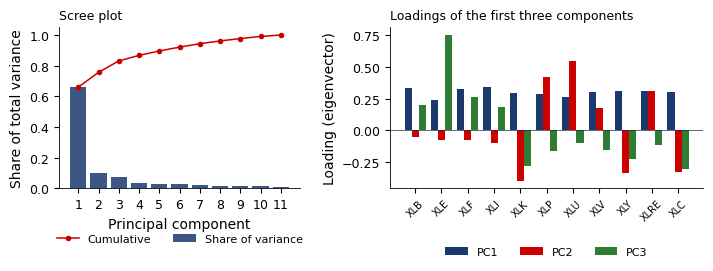

{'T': 2073,
 'share1': np.float64(0.6598485852014292),
 'share2': np.float64(0.0967418826785423),
 'cum3': np.float64(0.8308601191485488),
 'corr_pc1_spy': np.float64(0.9539639295054083),
 'n_eig_gt1': 2,
 'nfac': {'T': 2073,
  'N': 11,
  'kaiser': 2,
  'bai_ng': 5,
  'ahn_horenstein': 1,
  'eig': [7.258, 1.064, 0.817, 0.399, 0.317, 0.275],
  'er': [6.82, 1.3, 2.05, 1.26, 1.15]}}

In [22]:
# Rezolvare
def b3_pca():
    vals, vecs, r, c1 = pca_sectors()
    share = vals / vals.sum()
    S = [s + '.US' for s in SECTORS_ALL]
    return dict(T=len(r), share1=share[0], share2=share[1], cum3=share[:3].sum(), corr_pc1_spy=c1,
                n_eig_gt1=int((vals > 1).sum()), nfac=n_factors(r[S].values, 5))


def fig_pca():
    vals, vecs, r, c1 = pca_sectors()
    share = vals / vals.sum()
    fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.0), gridspec_kw={'width_ratios': [1, 1.3]})
    k = np.arange(1, len(vals) + 1)
    axes[0].bar(k, share, color=MainBlue, alpha=0.85, label='Share of variance')
    axes[0].plot(k, np.cumsum(share), color=IDAred, marker='o', ms=3, label='Cumulative')
    axes[0].set_xlabel('Principal component')
    axes[0].set_ylabel('Share of total variance')
    axes[0].set_xticks(k)
    axes[0].set_title('Scree plot', fontsize=9, loc='left')
    legend_outside_bottom(axes[0], ncol=2, y=-0.22)
    x = np.arange(len(SECTORS_ALL))
    for j, c in enumerate([MainBlue, IDAred, Forest]):
        axes[1].bar(x + (j - 1) * 0.27, vecs[:, j], 0.27, color=c, label=f'PC{j + 1}')
    axes[1].axhline(0, color=Gray, lw=0.5)
    axes[1].set_xticks(x, SECTORS_ALL, rotation=45, fontsize=7)
    axes[1].set_ylabel('Loading (eigenvector)')
    axes[1].set_title('Loadings of the first three components', fontsize=9, loc='left')
    legend_outside_bottom(axes[1], ncol=3, y=-0.3)
    plt.tight_layout()
    save_fig('ch3_pca')
    return dict(start=str(r.index[0].date()), end=str(r.index[-1].date()), T=len(r),
                share=[float(s) for s in share[:5]], cum3=float(share[:3].sum()), corr_pc1_spy=float(c1),
                load_pc2=dict(zip(SECTORS_ALL, np.round(vecs[:, 1], 3))),
                load_pc1=dict(zip(SECTORS_ALL, np.round(vecs[:, 0], 3))))


fig_pca()
b3_pca()

### B4. Beta CAPM pentru blue chips de la BVB [Propus]

- **Întrebările**

  - cît de sensibile sînt blue chips de la BVB la indicele BET?

  - cum deplasează prețurile neactualizate (stale prices) beta zilnic?

- **Date**: 11 blue chips (prețuri de închidere ajustate) și indicele BET; fiecare acțiune aliniată separat cu BET, în zilele comune; randamente logaritmice zilnice de la 6 ianuarie 2015 (sau de la listare) la 18 septembrie 2026; un $R_f$ constant se anulează

**Exemplu de curățare: DIGI în jurul datei de 23 mai 2017**

  Data        $r_{\text{DIGI}}$   BET$_{t-1}$   BET$_t$   BET$_{t+1}$ păstr.
  -------- ------------------------- --------------------------- --------------------------- --------------------------- --------
  19 mai      $1{,}78\%$      $-0{,}31\%$      $0{,}65\%$      $0{,}22\%$ da
  22 mai      $2{,}73\%$     $0{,}65\%$     $0{,}22\%$     $0{,}05\%$ da
  23 mai     $-658{,}7\%$     $0{,}22\%$     $0{,}05\%$     $0{,}48\%$ nu
  24 mai     $-2{,}97\%$     $0{,}05\%$     $0{,}48\%$     $0{,}48\%$ da
  25 mai     $1{,}74\%$     $0{,}48\%$     $0{,}48\%$     $0{,}66\%$ da

- O eroare de scară în primele înregistrări (închiderile din 17--22 mai sînt de circa 725 de ori mai mari) creează un randament log de $-6{,}59$; ziua se elimină

- Lead-ul și lag-ul zilelor păstrate folosesc totuși BET din 23 mai: formați-le înainte de eliminare

- **Cerințe**

  1.  Construiți randamentul BET din ziua următoare (lead) și din ziua anterioară (lag) pe calendarul complet al fiecărei perechi, apoi eliminați zilele cu $|r_t| > 0{,}5$ pentru acțiune sau BET; raportați zilele eliminate.

  2.  Estimați fiecare beta prin OLS pe BET, cu erori Newey--West (regula pentru numărul de laguri) și $R^2$.

  3.  Calculați valorile beta Vasicek Bayes empiric ([A3](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-A3)), cu cele 11 acțiuni ca secțiune transversală.

  4.  Estimați valorile beta Dimson, cu BET la $t-1$, $t$ și $t+1$ ([[prețuri neactualizate (stale prices) și beta Dimson]{style="color: MainBlue"}](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=sem3p15)).

- **De raportat**: tabel: OLS, Vasicek, Dimson; grafic: OLS cu intervale Newey--West de 95%

- **Interpretare**

  - la ce acțiuni schimbă cel mai mult corecția Dimson valoarea beta?

  - de ce tocmai la aceste acțiuni?

- Model: [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-B1), [A3](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-A3); Notebook: secțiunea [B4](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-B4)

[Exercițiul B4 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-B4)

In [23]:
# Codul vostru aici


## Partea C — întrebări deschise și critica unui răspuns AI

### C2. Prime factoriale la Bursa de Valori București [Propus]

- **Întrebarea**: generează momentum ([Jegadeesh & Titman (1993)](https://doi.org/10.1111/j.1540-6261.1993.tb04702.x)) și beta mic prime în rîndul acțiunilor blue chip de la BVB?

- **Date**: prețuri ajustate de sfîrșit de lună ale celor 10 blue chips din [C1](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-C1) și BET, decembrie 2015 -- august 2026 (septembrie 2026 incomplet); randamente lunare simple; randamentul FP din septembrie 2023 ($|r| > 50\%$, eveniment corporativ neajustat în serie) este tratat ca lipsă pentru semnale și randamente de deținere

- **Reguli fixate dinainte**

  - semnalul și beta folosesc informația pînă la sfîrșitul lui $t-1$ (cronologia din [C1](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-C1))

  - cel puțin 6 acțiuni disponibile; egalitățile se departajează după simbol

  - un randament de deținere lipsă se exclude din media părții respective

**Clasamentul pentru august 2026**

  Acțiunea                      Semnal Parte
  ---------- ------------------------- -------
  EL            $129{,}9\%$ long
  TGN           $127{,}3\%$ long
  DIGI          $113{,}2\%$ long
  SNG           $88{,}9\%$ 
  BRD           $87{,}8\%$ 
  SNN           $75{,}5\%$ 
  TEL           $66{,}1\%$ 
  FP            $51{,}0\%$ short
  TLV          $48{,}5\%$ short
  SNP          $46{,}6\%$ short

- Semnalul: randamentul compus din august 2025 -- iunie 2026, cunoscut la sfîrșitul lui iulie 2026

- **Cerințe**

  1.  Construiți momentum 12--1 (specificația din [C1](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-C1)): long primele 3, short ultimele 3, ponderi egale.

  2.  Construiți portofoliul beta mic: estimați beta pe BET pe ferestre mobile de 36 de luni (cel puțin 18 luni, pînă la $t-1$); long cele 3 cu beta cel mai mic, short cele 3 cu beta cel mai mare; un spread nescalat, nu BAB-ul neutru față de beta al lui [Frazzini & Pedersen (2014)](https://doi.org/10.1016/j.jfineco.2013.10.005).

  3.  Raportați perioadele, $T$, media anuală, volatilitatea și $t$ Newey--West (3 laguri); comparați $t$ cu $1{,}96$ și $3$; reprezentați spread-urile cumulate.

  4.  Discutați survivorship bias (blue chips de azi, alese retrospectiv), restricțiile la vînzarea în lipsă, costurile și lichiditatea.

  5.  Extindere: identificați surse publice pentru capitalul propriu contabil și numărul de acțiuni, necesare unui factor de valoare la BVB.

- **Livrabil**: un folder Quantlet în repository-ul propriu (script, sursa datelor și descriere scurtă) și un slide cu concluzia și principala ei limită

- Model: [B4](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-B4), [C1](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-C1); Notebook: Partea C

[Exercițiul C2 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-C2)

In [24]:
# Codul vostru aici


### C1. Critica unui backtest de momentum scris de AI [Propus]

- **Strategia dorită de student** (specificația): momentum 12--1 ([[momentum și look-ahead bias]{style="color: MainBlue"}](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=sem3p11)); o acțiune este eligibilă dacă există semnalul și prețul de la sfîrșitul lui $t-1$; long primele 3, short ultimele 3, ponderi egale, randamente simple ale lunii $t$

- **Date**: 10 blue chips (TLV, SNP, BRD, TGN, FP, SNG, SNN, EL, DIGI, TEL; H2O exclus: listat în iulie 2023), sfîrșit de lună, decembrie 2015 -- august 2026; randamentul FP din septembrie 2023 ($|r| > 50\%$, eveniment corporativ neajustat în serie) se tratează ca lipsă

- **Cerințe**

  1.  Verificați momentul semnalului, agregarea randamentelor între acțiuni și citarea; enumerați toate erorile găsite.

  2.  Pentru fiecare eroare, precizați cum ați detecta-o: un test, o cifră publicată sau lucrarea însăși.

  3.  Raportați codul corectat, media și volatilitatea anuale, numărul de luni și statistica t a mediei (Newey--West, 3 laguri).

  4.  Notați fiecare eroare în formatul `AI_ERRORS.md`: cerere, răspuns, eroare, cum ați găsit-o, corecția.

- **De raportat**: codul corectat, patru statistici și `AI_ERRORS.md`

<!-- -->

- $t-12, \dots, t-2$

- $t-1$

- $t$

- semnal

- pauză

- deținere

- clasament la sfîrșitul lui $t-1$

<!-- -->

- **Interpretare**

  - se confirmă „circa 48% pe an"?

  - la ce prag ($1{,}96$ sau $3$) este semnificativă prima corectată?

- Codul AI rulează de obicei fără mesaj de eroare: erorile sînt de fond (financiare), nu de sintaxă

- Model: [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-B1); Notebook: secțiunea [C1](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-C1)

[Exercițiul C1 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-C1)

In [25]:
# Codul vostru aici


### C3. Se replică factorii americani? Proiect în etape [Propus]

- **Context**: studiul de caz din curs, [Jensen, Kelly & Pedersen (2023)](https://doi.org/10.1111/jofi.13249): $82{,}4\%$ dintre factorii americani păstrează un alfa CAPM semnificativ într-un model ierarhic Bayes empiric, față de $75{,}6\%$ cu Benjamini--Yekutieli și $35\%$ la [Hou, Xue & Zhang (2020)](https://doi.org/10.1093/rfs/hhy131) (Figura 1)

- **Datele**: sortările univariate ponderate după valoare din [Kenneth French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html), iulie 1963 -- iulie 2026, și Mkt-RF din setul cu trei factori; extremele long--short pe 15 caracteristici

  - 30% extreme: mărime, book-to-market, profitabilitate operațională, investiții, profit/preț, cash flow/preț, dividend/preț; 20% extreme: acumulări, emisiuni nete de acțiuni, beta de piață, varianță, varianță reziduală; 10% extreme: randamentele anterioare din lunile 12--2 (momentum 12--1 din [[momentum și look-ahead bias]{style="color: MainBlue"}](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=sem3p11)), 1--0 și 60--13

- **Etapa 1, construcția și ratele frecventiste**

  1.  Construiți cei 15 factori, cu poziție long pe partea cu randamentul mai mare în articolul original; citați acel articol pentru fiecare semn și notați anul final al eșantionului și data publicării în tabelul factorilor.

  2.  Regresați fiecare factor pe Mkt-RF, rescalați-l la o volatilitate reziduală lunară de $10\%/\sqrt{12}$ (Secțiunea II.A a articolului), raportați $\hat\alpha$, $t$ și rata de replicare OLS ($t \ge 1{,}96$).

  3.  Aplicați Benjamini--Yekutieli la 5% și raportați $|t|$ critic și rata.

- **Etapa 2, teme și modelul ierarhic**

  4.  Construiți dendrograma Ward pe distanța $1 - $ corelația reziduurilor CAPM; comparați-o cu temele articolului (`Cluster Labels.csv`, [codul autorilor](https://github.com/bkelly-lab/ReplicationCrisis)).

  5.  Construiți $\mathbf{M}$ ($15 \times J$), matricea apartenenței la teme; estimați $\tau_c, \tau_w$ prin verosimilitate maximă pentru $\hat{\boldsymbol\alpha} \sim N(\mathbf{0}, \mathbf{M}\mathbf{M}^\top\tau_c^2 + \mathbf{I}\tau_w^2 + \hat{\boldsymbol\Sigma}/T)$, raportați dacă estimația atinge frontiera $\tau_c = 0$; calculați mediile și varianțele a posteriori (Propoziția 4) și rata Bayes empiric ($z$ a posteriori $\ge 1{,}96$).

- **Etapa 3, sensibilitate**: calculați rata cu o singură temă și în funcție de $\tau_c$, apoi False Discovery Rate (FDR) bayesian (Propoziția 5)

- **Etapa 4, scăderea după eșantion**: estimați valorile alfa în anii eșantionului original (de la iulie 1963) și după, cu cel puțin 60 de luni în fiecare; regresați prin GLS fezabil valorile alfa ulterioare pe cele din eșantion, cu inversa covarianței factorilor; comparați panta cu $0{,}26$ (Figura 8)

- **De raportat**: un tabel al factorilor (an final al eșantionului, data publicării, alfa, $t$, temă, media a posteriori, $z$), ratele, alături de cele din Figura 1, $\hat\tau$, alături de valorile din Tabelul I, dendrograma și panta; păstrați separat cifrele articolului și cele ale cursului

- Model: [A3](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-A3), [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-A1) și studiul de caz din curs

[Exercițiul C3 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar3_modele_factoriale_ro.pdf#nameddest=ex-C3)

In [26]:
# Your code here
